In [1]:
!pip install geopandas -q
!pip install arviz==0.23.0 -q
!pip install pymc -q
!pip install nutpie -q
!pip install numpyro -q

In [2]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
import libpysal.weights as lw
from libpysal.weights import Queen

import os
#import warnings
import arviz as az
import pymc as pm
import pytensor.tensor as pt

import networkx as nx
import nutpie

from sklearn.preprocessing import StandardScaler

from esda.moran import Moran

from scipy import sparse
from scipy.linalg import solve
from scipy.sparse.linalg import spsolve
#warnings.filterwarnings("ignore")

In [3]:
import sys

# Python version
print(f"Python Version: {sys.version.split(' ')[0]}")

# Imported libraries versions
print("\nImported Library Versions:")
for module_name in sorted(sys.modules.keys()):
    if any(keyword in module_name for keyword in ['pandas', 'numpy', 'scipy', 'matplotlib', 'geopandas', 'arviz', 'pymc', 'nutpie', 'numpyro', 'libpysal', 'networkx', 'sklearn', 'esda', 'statsmodels']):
        try:
            module = sys.modules[module_name]
            if hasattr(module, '__version__'):
                print(f"{module_name}: {module.__version__}")
        except Exception:
            # Some modules might cause issues when trying to access __version__ or other attributes
            pass


Python Version: 3.13.15

Imported Library Versions:
arviz: 0.23.0
arviz.data.base: 0.23.0
esda: 2.9.0
geopandas: 1.1.4
libpysal: 4.14.1
matplotlib: 3.10.0
matplotlib_inline: 0.2.2
networkx: 3.6.1
numpy: 2.1.3
numpy._core: 2.1.3
numpy._core._multiarray_umath: 3.1
numpy.core: 2.1.3
numpy.f2py: <module 'numpy.f2py.__version__' from '/usr/local/lib/python3.13/dist-packages/numpy/f2py/__version__.py'>
numpy.f2py.auxfuncs: <module 'numpy.f2py.__version__' from '/usr/local/lib/python3.13/dist-packages/numpy/f2py/__version__.py'>
numpy.f2py.capi_maps: <module 'numpy.f2py.__version__' from '/usr/local/lib/python3.13/dist-packages/numpy/f2py/__version__.py'>
numpy.f2py.cb_rules: <module 'numpy.f2py.__version__' from '/usr/local/lib/python3.13/dist-packages/numpy/f2py/__version__.py'>
numpy.f2py.cfuncs: <module 'numpy.f2py.__version__' from '/usr/local/lib/python3.13/dist-packages/numpy/f2py/__version__.py'>
numpy.f2py.common_rules: <module 'numpy.f2py.__version__' from '/usr/local/lib/python3.13

/tmp/ipykernel_3799/2763113741.py:12: DeprecationWarning: numpy.core is deprecated and has been renamed to numpy._core. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.__version__.
  if hasattr(module, '__version__'):
/tmp/ipykernel_3799/2763113741.py:13: DeprecationWarning: numpy.core is deprecated and has been renamed to numpy._core. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If n

In [4]:
#df_gpkg = gpd.read_file("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/京都市国勢統計区.gpkg")
#df = pd.read_excel("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/解析用国勢統計区データ.xlsx")

In [5]:
#df_gpkgの不要なカラムの削除
#df_gpkg = df_gpkg.drop(["Name", "descriptio","timestamp", "begin", "end", "altitudeMo", "tessellate", "extrude", "visibility", "drawOrder", "icon"], axis=1)

In [6]:
#idが二つのファイルで一致するか確認

#df["id"] = df["id"].astype(int)
#df_gpkg["id"] = df_gpkg["id"].astype(int)

#assert df["id"].is_unique
#assert df_gpkg["id"].is_unique
#assert set(df["id"]) == set(df_gpkg["id"])

In [7]:
#df_gpkg = df_gpkg.merge(df, on=["id", "名称"], how="left", validate="one_to_one")

In [8]:
#df_gpkg.crs

In [9]:
#df_gpkg.to_file("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/解析用結合データ.geojson", driver="GeoJSON")

In [10]:
#df_gpkg = gpd.read_file("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/解析用結合データ.geojson")

In [11]:
df_gpkg = gpd.read_file("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/解析用結合データ②.geojson")

In [12]:
df_gpkg.head()

,名称,id,国勢統計区,行政区,異状死再カウント,人口総数（オフセット）,男性の割合,65歳以上単身者率,公的借家率,外国人割合,...,単位面積医療機関数,単位面積医療機関数対数変換（log1p）,単位面積バス停数,単位面積バス停数対数変換（logp1）,単位面積電車駅数,単位面積電車駅数対数変換（log1p）,欠損値クイーン型補間後公示地価（円/m2）,公示地価欠損有無,公示地価欠損中央値代入対数変換,geometry
0,北_待鳳,0,待鳳,北,8,9851,0.477312,0.138616,0.000000,0.019287,...,8.866995,2.289195,8.866995,2.289195,0.0,0.0,253000.0,0,12.441145,"MULTIPOLYGON Z (((135.73814 35.04477 100, 135...."
1,北_紫竹,1,紫竹,北,6,6655,0.462660,0.124963,0.000000,0.017581,...,18.739353,2.982614,23.850085,3.212861,0.0,0.0,315000.0,0,12.660328,"MULTIPOLYGON Z (((135.74857 35.04626 100, 135...."
2,北_紫野,2,紫野,北,4,7685,0.464802,0.162380,0.016603,0.021861,...,16.420361,2.857640,8.210181,2.220309,0.0,0.0,247500.0,0,12.419166,"MULTIPOLYGON Z (((135.74523 35.03544 100, 135...."
3,北_楽只,3,楽只,北,3,2273,0.466344,0.202713,0.223674,0.021557,...,8.064516,2.204367,12.096774,2.572366,0.0,0.0,243000.0,0,12.400817,"MULTIPOLYGON Z (((135.73997 35.03853 100, 135...."
4,北_鷹峯,4,鷹峯,北,7,3989,0.484583,0.143010,0.000000,0.019554,...,0.147514,0.137598,0.737572,0.552489,0.0,0.0,168000.0,0,12.031719,"MULTIPOLYGON Z (((135.71805 35.06987 100, 135...."


In [13]:
df_gpkg.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [14]:
# 最終チェック
assert len(df_gpkg) == 227
assert list(df_gpkg["id"]) == list(range(227))
assert df_gpkg["名称"].is_unique

In [15]:
#隣接行列の作成
w_queen = Queen.from_dataframe(df_gpkg, ids=df_gpkg["id"].to_list())

In [16]:
#念のための確認
assert list(w_queen.id_order) == list(df_gpkg["id"])

In [17]:
#スケーリングファクター計算
def scaling_factor_sp(A):
    num_neighbors = A.sum(axis=1)
    A = sparse.csc_matrix(A)
    D = sparse.diags(num_neighbors, format="csc")
    Q = D - A

    Q_perturbed = Q + sparse.diags(np.ones(Q.shape[0])) * max(Q.diagonal()) * np.sqrt(np.finfo(np.float64).eps)

    n = Q_perturbed.shape[0]
    b = sparse.identity(n, format="csc")
    Sigma = spsolve(Q_perturbed, b)
    A = np.ones(n)
    W = Sigma @ A.T
    Q_inv = Sigma - np.outer(W * solve(A @ W, np.ones(1)), W.T)

    return np.exp(np.sum(np.log(np.diag(Q_inv))/n))

In [18]:
w_queen_np = w_queen.full()[0]
scaling_factor = scaling_factor_sp(w_queen_np)
print(scaling_factor)

0.38976731151419813


In [19]:
df_gpkg.columns

Index(['名称', 'id', '国勢統計区', '行政区', '異状死再カウント', '人口総数（オフセット）', '男性の割合',
       '65歳以上単身者率', '公的借家率', '外国人割合', '母子世帯割合', '失業率 = 完全失業者数 /労働力人口',
       '短期居住者割合（5年未満）', '高卒未満＝（小学校卒業+中学校卒業）/卒業者', '単位面積医療機関数',
       '単位面積医療機関数対数変換（log1p）', '単位面積バス停数', '単位面積バス停数対数変換（logp1）', '単位面積電車駅数',
       '単位面積電車駅数対数変換（log1p）', '欠損値クイーン型補間後公示地価（円/m2）', '公示地価欠損有無',
       '公示地価欠損中央値代入対数変換', 'geometry'],
      dtype='object')

In [20]:
#変数準備
scaler = StandardScaler()

covariate_cols = [
    "男性の割合",
    "65歳以上単身者率",
    "公的借家率",
    "外国人割合",
    "母子世帯割合",
    "失業率 = 完全失業者数 /労働力人口",
    "短期居住者割合（5年未満）",
    "高卒未満＝（小学校卒業+中学校卒業）/卒業者",
    "単位面積医療機関数対数変換（log1p）",
    "単位面積バス停数対数変換（logp1）",
    "単位面積電車駅数対数変換（log1p）",
    "公示地価欠損中央値代入対数変換"]

indicator_cols = ["公示地価欠損有無"]

X_cont = scaler.fit_transform(df_gpkg[covariate_cols])
X_indicator = df_gpkg[indicator_cols].to_numpy()

X = np.column_stack([X_cont, X_indicator])

y = df_gpkg["異状死再カウント"].to_numpy()
off_set = np.log(df_gpkg["人口総数（オフセット）"].to_numpy())

model_cols = covariate_cols + indicator_cols

In [21]:
model_cols

['男性の割合',
 '65歳以上単身者率',
 '公的借家率',
 '外国人割合',
 '母子世帯割合',
 '失業率 = 完全失業者数 /労働力人口',
 '短期居住者割合（5年未満）',
 '高卒未満＝（小学校卒業+中学校卒業）/卒業者',
 '単位面積医療機関数対数変換（log1p）',
 '単位面積バス停数対数変換（logp1）',
 '単位面積電車駅数対数変換（log1p）',
 '公示地価欠損中央値代入対数変換',
 '公示地価欠損有無']

In [22]:
#モデル定義
n_area = len(y)
n_cov = X.shape[1]

coords = {"area": np.arange(n_area), "covariate": model_cols}

with pm.Model(coords=coords) as bym2_model_possion:
    #データ
    X_data = pm.Data("X_data", X, dims=("area", "covariate"))
    y_obs = pm.Data("y_obs", y, dims="area")
    offset_data = pm.Data("offset_data", off_set, dims="area")

    #固定効果
    intercept = pm.Normal("intercept", mu=0, sigma=1)
    beta = pm.Normal("beta", mu=0, sigma=1, dims="covariate")

    #ミックス割合
    rho = pm.Beta("rho", 0.5, 0.5)

    #空間効果
    phi = pm.ICAR("phi", W=w_queen_np, dims="area")

    #非空間効果
    theta = pm.Normal("theta", mu=0, sigma=1, dims="area")

    #スケール調整
    sigma = pm.HalfNormal("sigma", sigma=1)

    #混合効果パート
    mixture = pm.Deterministic("mixture", pt.sqrt(1 - rho) * theta + pt.sqrt(rho / scaling_factor) * phi, dims="area")

    #線形回帰
    mu = pm.Deterministic("mu", pt.exp(intercept + offset_data + pm.math.dot(X_data, beta) + sigma * mixture), dims="area")

    alpha = pm.HalfNormal("alpha", sigma=5)

    y_i = pm.Poisson("y_i", mu=mu, observed=y_obs, dims="area")

In [23]:
with bym2_model_possion:
    idata_p = pm.sample(chains=4,
                      target_accept=0.95,
                      tune=3000,
                      draws=3000,
                      #nuts_sampler="numpyro",
                      random_seed=321)

Output()

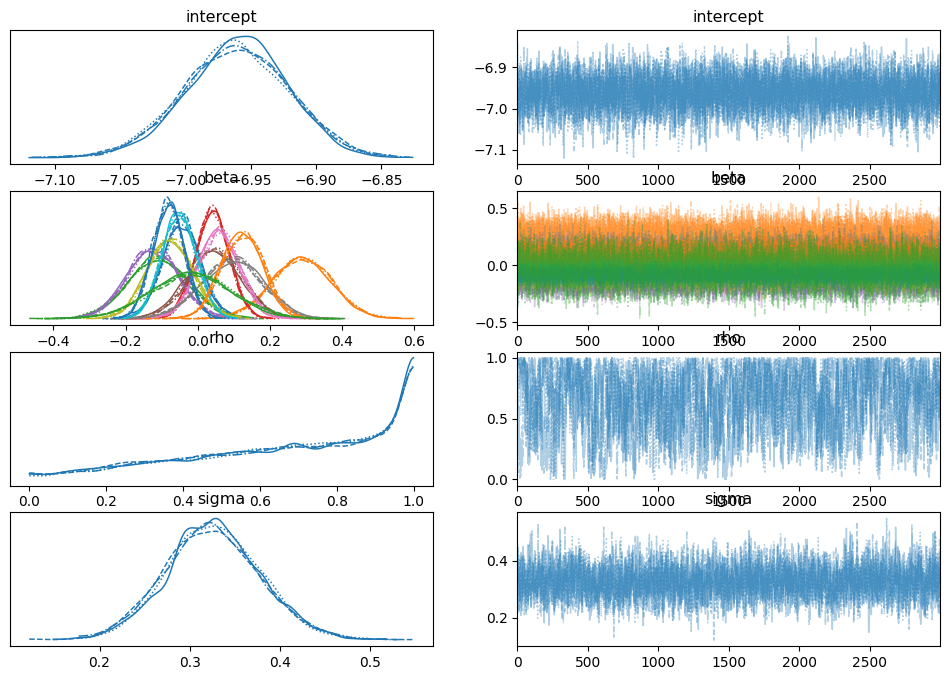

In [24]:
az.plot_trace(idata_p, var_names=["intercept", "beta", "rho", "sigma"]);

In [25]:
summary_p = az.summary(idata_p)
summary_p[summary_p["r_hat"] > 1.01].sort_values("r_hat", ascending=False)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat


In [26]:
print("max r_hat:", summary_p["r_hat"].max())
print("n r_hat > 1.01:", (summary_p["r_hat"] > 1.01).sum())
print("n r_hat is NaN:", summary_p["r_hat"].isna().sum())

print("ess bulk:", summary_p["ess_bulk"].min())
print("ess tail:", summary_p["ess_tail"].min())

print("diverging:", idata_p.sample_stats["diverging"].sum().values)

max r_hat: 1.01
n r_hat > 1.01: 0
n r_hat is NaN: 0
ess bulk: 611.0
ess tail: 1110.0
diverging: 0


In [27]:
az.summary(idata_p, var_names=["intercept", "beta", "rho", "sigma"], hdi_prob=0.95)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
intercept,-6.961,0.040,-7.039,-6.882,0.001,0.000,5988.0,8030.0,1.00
beta[男性の割合],-0.045,0.052,-0.151,0.054,0.001,0.000,5574.0,8338.0,1.00
beta[65歳以上単身者率],0.288,0.083,0.129,0.455,0.001,0.001,4401.0,7042.0,1.00
beta[公的借家率],-0.111,0.084,-0.275,0.054,0.001,0.001,3857.0,6330.0,1.00
beta[外国人割合],0.040,0.047,-0.051,0.134,0.001,0.000,5492.0,7913.0,1.00
beta[母子世帯割合],-0.124,0.072,-0.262,0.018,0.001,0.001,4688.0,8457.0,1.00
beta[失業率 = 完全失業者数 /労働力人口],0.047,0.074,-0.099,0.190,0.001,0.001,5744.0,7523.0,1.00
beta[短期居住者割合（5年未満）],0.059,0.058,-0.055,0.170,0.001,0.000,3935.0,6722.0,1.00
beta[高卒未満＝（小学校卒業+中学校卒業）/卒業者],0.093,0.085,-0.080,0.250,0.001,0.001,5673.0,7554.0,1.00
beta[単位面積医療機関数対数変換（log1p）],-0.076,0.063,-0.196,0.051,0.001,0.001,3687.0,6913.0,1.00


In [28]:
with bym2_model_possion:
    idata_p = pm.sample_posterior_predictive(idata_p, var_names=["y_i"], predictions=False, extend_inferencedata=True, random_seed=321)

Output()

In [29]:
idata_p.to_netcdf("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/inference_data_p.nc")

'/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/inference_data_p.nc'

In [30]:
with bym2_model_possion:
    idata_p_2 = pm.sample(chains=4,
                      target_accept=0.95,
                      tune=3000,
                      draws=3000,
                      #nuts_sampler="numpyro",
                      random_seed=123)

Output()

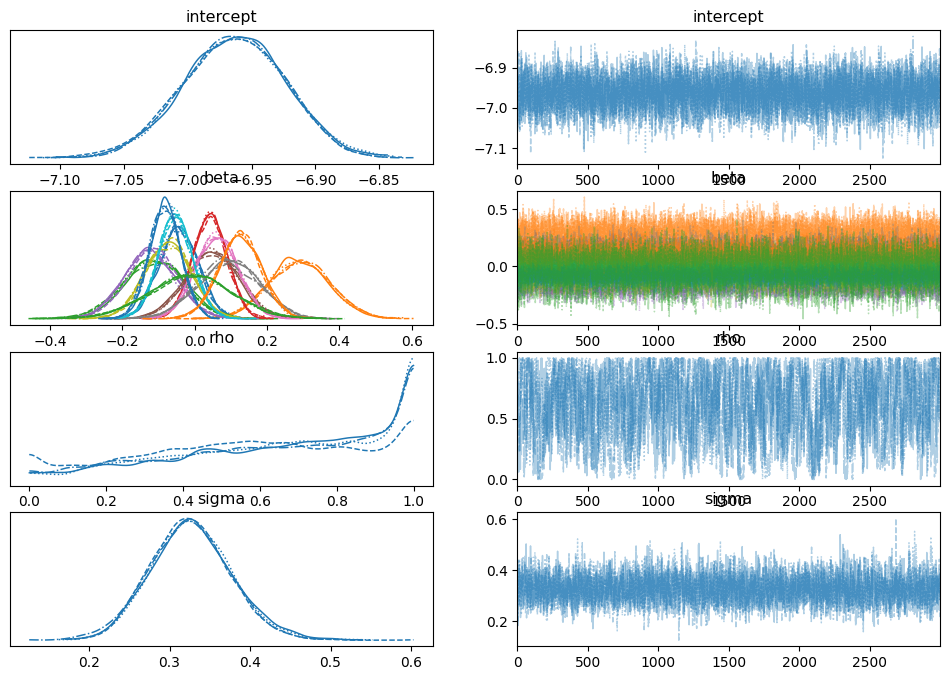

In [31]:
az.plot_trace(idata_p_2, var_names=["intercept", "beta", "rho", "sigma"]);

In [32]:
summary_p_2 = az.summary(idata_p_2)
summary_p_2[summary_p_2["r_hat"] > 1.01].sort_values("r_hat", ascending=False)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat


In [33]:
print("max r_hat:", summary_p_2["r_hat"].max())
print("n r_hat > 1.01:", (summary_p_2["r_hat"] > 1.01).sum())
print("n r_hat is NaN:", summary_p_2["r_hat"].isna().sum())

print("ess bulk:", summary_p_2["ess_bulk"].min())
print("ess tail:", summary_p_2["ess_tail"].min())

print("diverging:", idata_p_2.sample_stats["diverging"].sum().values)

max r_hat: 1.01
n r_hat > 1.01: 0
n r_hat is NaN: 0
ess bulk: 545.0
ess tail: 937.0
diverging: 0


In [34]:
az.summary(idata_p_2, var_names=["intercept", "beta", "rho", "sigma"], hdi_prob=0.95)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
intercept,-6.963,0.040,-7.041,-6.886,0.001,0.000,5382.0,7647.0,1.00
beta[男性の割合],-0.044,0.054,-0.145,0.065,0.001,0.000,4910.0,7731.0,1.00
beta[65歳以上単身者率],0.289,0.084,0.123,0.450,0.001,0.001,4006.0,6505.0,1.00
beta[公的借家率],-0.114,0.083,-0.279,0.047,0.001,0.001,3689.0,6362.0,1.00
beta[外国人割合],0.041,0.048,-0.051,0.135,0.001,0.000,4897.0,7864.0,1.00
beta[母子世帯割合],-0.122,0.072,-0.267,0.016,0.001,0.001,4234.0,7762.0,1.00
beta[失業率 = 完全失業者数 /労働力人口],0.049,0.074,-0.094,0.196,0.001,0.001,6650.0,8560.0,1.00
beta[短期居住者割合（5年未満）],0.061,0.059,-0.054,0.175,0.001,0.000,4391.0,7108.0,1.00
beta[高卒未満＝（小学校卒業+中学校卒業）/卒業者],0.093,0.084,-0.065,0.261,0.001,0.001,5205.0,7493.0,1.00
beta[単位面積医療機関数対数変換（log1p）],-0.073,0.064,-0.200,0.050,0.001,0.001,3265.0,6607.0,1.00


In [35]:
with bym2_model_possion:
    idata_p_2 = pm.sample_posterior_predictive(idata_p_2, var_names=["y_i"], predictions=False, extend_inferencedata=True, random_seed=123)

Output()

In [36]:
idata_p_2.to_netcdf("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/inference_data_p_2.nc")

'/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/inference_data_p_2.nc'

In [37]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

X_vif = pd.DataFrame(X_cont, columns=covariate_cols)

vif_df = pd.DataFrame({
    "variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

vif_df.sort_values("VIF", ascending=False)

,variable,VIF
2,公的借家率,3.886277
1,65歳以上単身者率,3.804610
7,高卒未満＝（小学校卒業+中学校卒業）/卒業者,2.946729
5,失業率 = 完全失業者数 /労働力人口,2.529004
4,母子世帯割合,2.417066
8,単位面積医療機関数対数変換（log1p）,2.355626
6,短期居住者割合（5年未満）,1.920940
11,公示地価欠損中央値代入対数変換,1.765365
3,外国人割合,1.628820
0,男性の割合,1.623995
